# 03 · Preprocessing

How to clean a raw spectrum before measuring its peaks: remove the baseline, smooth the noise and normalise the scale.

1. Remove the baseline under the peaks
2. Smooth noise without flattening peaks
3. Normalise samples onto one scale
4. Chain the steps in the right order

Code: `src/spectro/preprocessing.py`.

## Setup

In [1]:
import matplotlib.pyplot as plt

from spectro import (
    Peak,
    estimate_baseline,
    make_spectrum,
    normalize,
    plot_spectrum,
    remove_baseline,
    smooth,
)

peaks = [
    Peak(center=3350, fwhm=300, height=0.6, shape="gaussian"),  # O–H
    Peak(center=2950, fwhm=40, height=0.4),  # C–H
    Peak(center=2870, fwhm=30, height=0.3),  # C–H
    Peak(center=1715, fwhm=25, height=0.9),  # C=O
    Peak(center=1100, fwhm=50, height=0.5, shape="lorentzian"),  # C–O
]
clean, true_peaks = make_spectrum(peaks)
raw, _ = make_spectrum(peaks, noise=0.01, baseline=(0.05, 0.1, -0.05), seed=0)

## 1. Remove the baseline under the peaks

A drifting background adds to every peak's height and area, so it has to go first. `estimate_baseline` fits a smooth curve along the bottom of the spectrum (arPLS by default); `remove_baseline` subtracts it. The narrow peaks come back almost exactly; the very broad O–H band near 3350 cm⁻¹ loses a little height, because a band 300 cm⁻¹ wide starts to look like background.

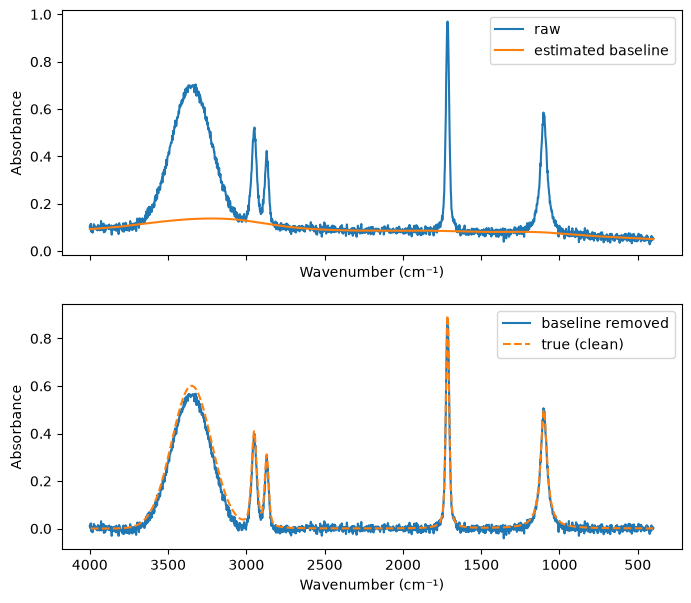

In [2]:
baseline = estimate_baseline(raw)
corrected = remove_baseline(raw)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
plot_spectrum(raw, ax=top, label="raw")
plot_spectrum(baseline, ax=top, label="estimated baseline")
top.legend()
plot_spectrum(corrected, ax=bottom, label="baseline removed")
plot_spectrum(clean, ax=bottom, label="true (clean)", linestyle="--")
bottom.legend();

## 2. Smooth noise without flattening peaks

Savitzky–Golay smoothing fits a small polynomial in a sliding window of `window` points. Here points are 2 cm⁻¹ apart and the C=O peak has FWHM 25 cm⁻¹ (about 12 points). A window well below that removes noise and keeps the peak; a window wider than the peak flattens it.

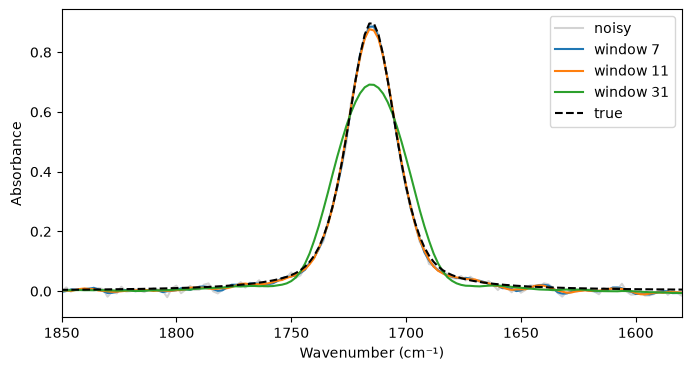

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_spectrum(corrected, ax=ax, label="noisy", color="lightgray")
for window in [7, 11, 31]:
    plot_spectrum(smooth(corrected, window=window), ax=ax, label=f"window {window}")
plot_spectrum(clean, ax=ax, label="true", color="black", linestyle="--")
ax.set_xlim(1850, 1580)
ax.legend();

## 3. Normalise samples onto one scale

A thicker or more concentrated sample gives a taller spectrum of the same shape. Normalising removes that overall scale, so the two samples below become the same. `"max"` is easiest to read; `"snv"` is common before classification.

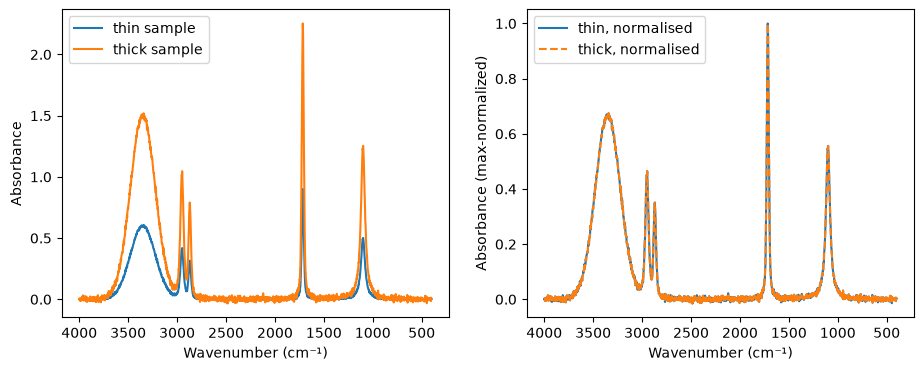

In [4]:
thin, _ = make_spectrum(peaks, noise=0.005, seed=1)
thick = thin.with_y(2.5 * thin.y)

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
plot_spectrum(thin, ax=left, label="thin sample")
plot_spectrum(thick, ax=left, label="thick sample")
left.legend()
plot_spectrum(normalize(thin), ax=right, label="thin, normalised")
plot_spectrum(normalize(thick), ax=right, label="thick, normalised", linestyle="--")
right.legend();

## 4. Chain the steps in the right order

Each function returns a new `Spectrum`, so the steps chain, and each one records itself in `metadata["preprocessing"]`. The order is baseline → smooth → normalise. Normalising first would divide by a value that includes the baseline: below, two samples with the same peaks but different baselines end up at different heights unless the baseline is removed first.

In [5]:
processed = normalize(smooth(remove_baseline(raw)))
processed.metadata["preprocessing"]

['remove_baseline(arpls)', 'smooth(11, 3)', 'normalize(max)']

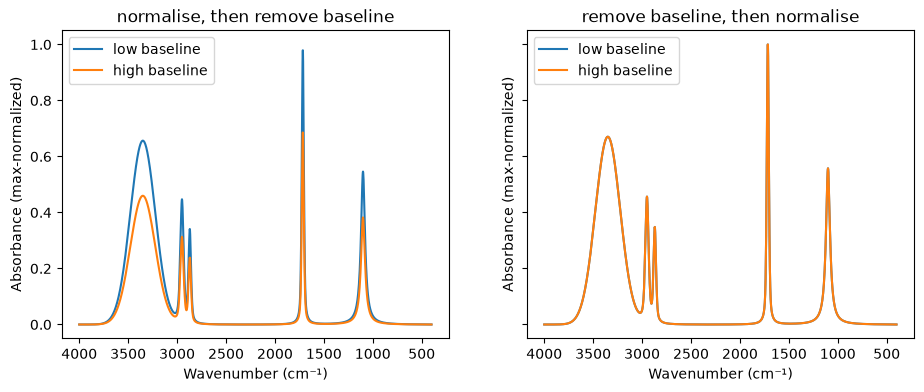

In [6]:
low, _ = make_spectrum(peaks, baseline=(0.0, 0.05))
high, _ = make_spectrum(peaks, baseline=(0.3, 0.3))

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for sample, name in [(low, "low baseline"), (high, "high baseline")]:
    plot_spectrum(remove_baseline(normalize(sample)), ax=left, label=name)
    plot_spectrum(normalize(remove_baseline(sample)), ax=right, label=name)
left.set_title("normalise, then remove baseline")
right.set_title("remove baseline, then normalise")
left.legend()
right.legend();